<a href="https://colab.research.google.com/github/anamika29lj/CSL701-CE22_Machine-Learning-Lab/blob/main/ML_Experiment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name : Anamika Jagram Lodhi

Roll No: CE22

Aim

To implement Support Vector Machine (SVM) for classification of the Iris dataset and visualize its decision boundary and compare it with a normal linear classification boundary.

## Objectives

1. To understand the concept of Support Vector Machine.
2. To implement SVM using Python.
3. To visualize the SVM decision boundary.
4. To identify the support vectors.
5. To compare the SVM boundary with a normal linear classification boundary.
6. To evaluate the performance of the classifiers.

# Relevant Theory

### Support Vector Machine

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification.

SVM finds a decision boundary that separates different classes while trying to maximize the distance, called the **margin**, between the classes.

The points closest to the decision boundary are called **support vectors**.

For a linear SVM, the decision boundary can be represented as:

$$
w^T x + b = 0
$$

where:

- $w$ = weight vector
- $x$ = input features
- $b$ = bias


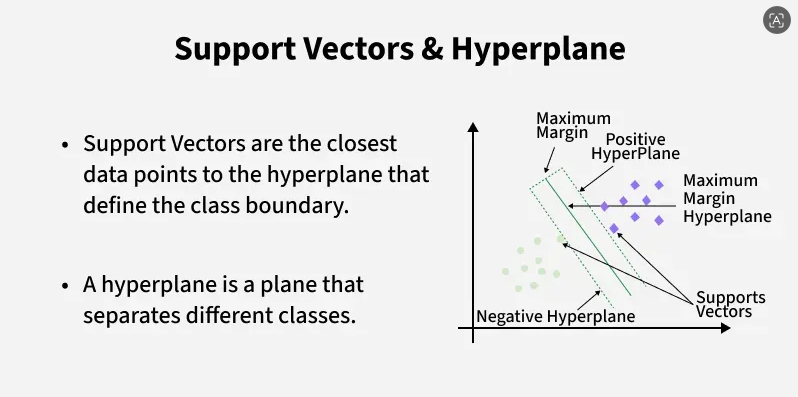
### Kernel

SVM can use different kernels to create decision boundaries.

Common kernels are:

- Linear
- Polynomial
- RBF
- Sigmoid

In this experiment, we mainly use the **Linear SVM** and **RBF SVM**.

---

# Dataset Information

Get the IRIS dataset from Kaggle using below link

https://www.kaggle.com/datasets/uciml/iris

The Iris dataset contains measurements of Iris flowers belonging to three classes:

- Iris-setosa
- Iris-versicolor
- Iris-virginica

The four features are:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

For visualization, we will use:

**Petal Length and Petal Width.**

# Task 1: Import Libraries and Load Dataset

Load the Iris dataset.

---

In [ ]:
# Task 1: Import Libraries and Load Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.datasets import load_iris

# Load Iris dataset from sklearn
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'])
df['Species'] = iris.target

# Map target numbers to species names
species_map = {0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'}
df['Species'] = df['Species'].map(species_map)

# Display first 5 rows
print(df.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa


# Task 2: Explore the Dataset

In [ ]:
# Task 2: Explore the Dataset

# Display first 5 rows
print("First 5 rows:")
print(df.head())

# Display last 5 rows
print("\nLast 5 rows:")
print(df.tail())

# Display shape
print("\nShape of dataset:")
print(df.shape)

# Display column names
print("\nColumn names:")
print(df.columns)

# Display information
print("\nDataset information:")
print(df.info())

# Display statistical summary
print("\nStatistical summary:")
print(df.describe())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display class counts
print("\nClass counts:")
print(df["Species"].value_counts())

First 5 rows:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa

Last 5 rows:
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm         Species
145            6.7           3.0            5.2           2.3  Iris-virginica
146            6.3           2.5            5.0           1.9  Iris-virginica
147            6.5           3.0            5.2           2.0  Iris-virginica
148            6.2           3.4            5.4           2.3  Iris-virginica
149            5.9           3.0            5.1           1.8  Iris-virginica

Shape of dataset:
(150, 5)

Column names:
Index(['SepalLengthCm',

# Task 3: Select Features and Target

Remove the `Id` column.

Select Remaining Features

In [ ]:
# Task 3: Select Features and Target

# The 'Id' column does not exist when loading Iris from sklearn, so df.drop('Id') is not needed.

# Select input features
X = df.drop("Species", axis=1)

# Select target
y = df["Species"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nFeature shape:")
print(X.shape)

print("\nTarget shape:")
print(y.shape)

Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Target:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

Feature shape:
(150, 4)

Target shape:
(150,)


# Task 4: Split and Scale the Data

Divide the dataset into training and testing sets.

In [ ]:
# Task 4: Split and Scale the Data

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create StandardScaler
scaler = StandardScaler()

# Scale training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale testing data
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (120, 4)
Testing data shape: (30, 4)


# Task 5: Implement Linear SVM

Create an SVM model using a **linear kernel**.

Make predictions.

In [ ]:
# Task 5: Implement Linear SVM

# Create Linear SVM model
svm_model = SVC(kernel="linear")

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_scaled)

print("Predicted values:")
print(y_pred_svm)

print("\nActual values:")
print(y_test.values)

Predicted values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa']

Actual values:
['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 

# Task 6: Evaluate SVM

### Calculate Accuracy

Calculate the accuracy of the SVM model.

### Confusion Matrix

Generate the confusion matrix to evaluate the classification results.

### Classification Report

Generate the classification report containing:

- Precision
- Recall
- F1-Score
- Support

---


In [ ]:
# Task 6: Evaluate SVM

# Calculate accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", accuracy_svm)

# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("\nConfusion Matrix:")
print(cm_svm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



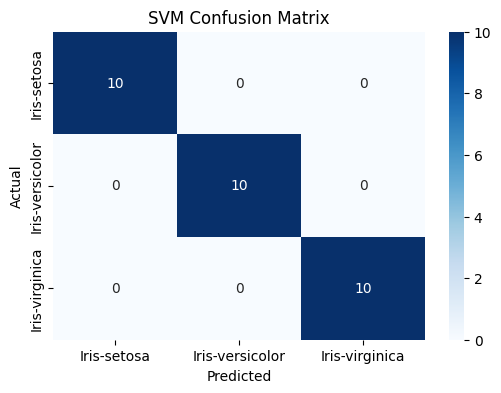

In [ ]:
# Plot Confusion Matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

# Task 7: Visualize SVM Decision Boundary

For visualization, we use only two features:

- Petal Length
- Petal Width

### Create the 2-D Dataset

Select **Petal Length** and **Petal Width** as the input features.

### Split the Data

Divide the 2-D dataset into training and testing sets.

### Scale the Data

Standardize the selected features before training the SVM model.

### Train SVM

Train an SVM classifier using a **linear kernel**.

### Plot Decision Boundary

Visualize the SVM decision boundary along with the data points.

---

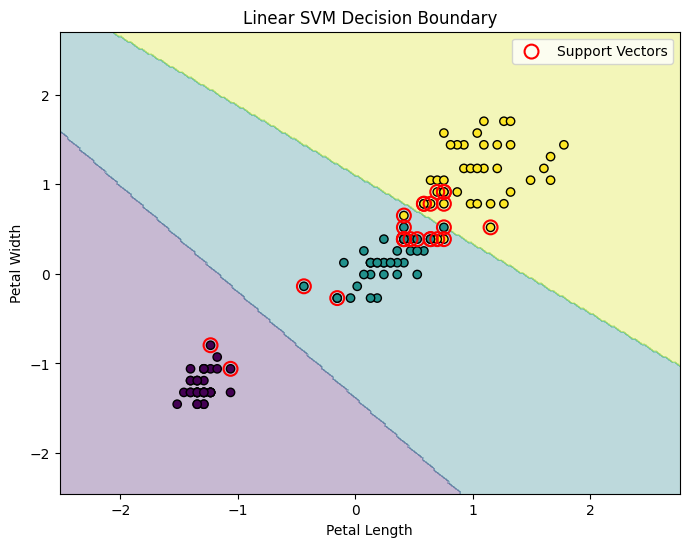

In [ ]:
# Task 7: Visualize SVM Decision Boundary

# Select two features
X_2d = df[["PetalLengthCm", "PetalWidthCm"]]

# Target
y_2d = df["Species"]

# Split data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Scale the data
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Train Linear SVM
svm_2d = SVC(kernel="linear")

svm_2d.fit(X_train_2d_scaled, y_train_2d)

# Create grid
x_min = X_train_2d_scaled[:, 0].min() - 1
x_max = X_train_2d_scaled[:, 0].max() + 1

y_min = X_train_2d_scaled[:, 1].min() - 1
y_max = X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict each point in grid (keep as 1D array initially)
Z = svm_2d.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

# Convert 1D predictions to numbers first
Z_num = pd.Categorical(Z, categories=svm_2d.classes_).codes

# Reshape the numeric codes back to the 2D grid shape
Z_num = Z_num.reshape(xx.shape)

# Convert class names into numbers for plotting
class_numbers = pd.Categorical(y_train_2d).codes

# Plot decision boundary
plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z_num,
    alpha=0.3
)

# Plot data points
scatter = plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=class_numbers,
    edgecolors="k"
)

# Plot support vectors
plt.scatter(
    svm_2d.support_vectors_[:, 0],
    svm_2d.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="red",
    linewidths=1.5,
    label="Support Vectors"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Linear SVM Decision Boundary")
plt.legend()

plt.show()

# Task 8: Normal Linear Classification Boundary

For comparison, we use **Logistic Regression** as a normal linear classifier.

Train a Logistic Regression model using the same two features and visualize its decision boundary.

---

Logistic Regression Accuracy: 0.9333333333333333


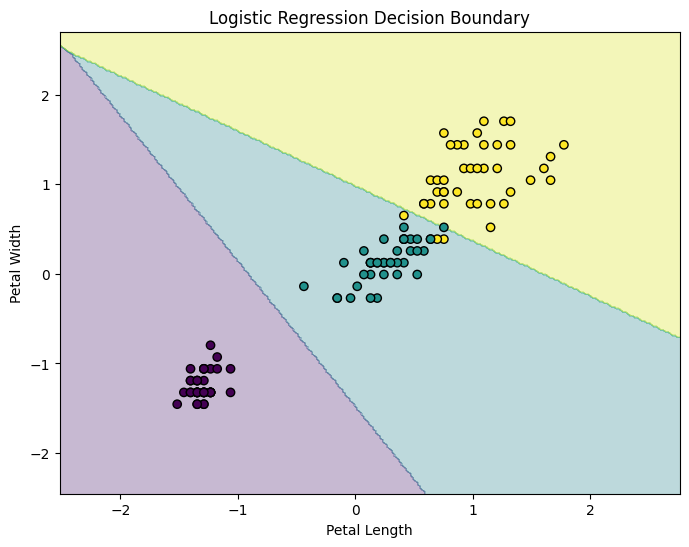

In [ ]:
# Task 8: Normal Linear Classification Boundary
# Using Logistic Regression

# Create Logistic Regression model
logistic_model = LogisticRegression(max_iter=200)

# Train model
logistic_model.fit(X_train_2d_scaled, y_train_2d)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test_2d_scaled)

# Accuracy
accuracy_logistic = accuracy_score(
    y_test_2d,
    y_pred_logistic
)

print("Logistic Regression Accuracy:", accuracy_logistic)

# Create grid
x_min = X_train_2d_scaled[:, 0].min() - 1
x_max = X_train_2d_scaled[:, 0].max() + 1

y_min = X_train_2d_scaled[:, 1].min() - 1
y_max = X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict grid points
Z = logistic_model.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

# Convert classes to numbers first (using the 1D predictions array)
Z_num = pd.Categorical(Z, categories=logistic_model.classes_).codes

# Reshape the numeric codes back to the 2D grid shape
Z_num = Z_num.reshape(xx.shape)

# Convert classes to numbers for plotting
class_numbers = pd.Categorical(y_train_2d).codes

# Plot
plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z_num,
    alpha=0.3
)

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=class_numbers,
    edgecolors="k"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Logistic Regression Decision Boundary")

plt.show()

# Task 9: Compare SVM and Normal Boundary

Plot both the **SVM** and **Logistic Regression** decision boundaries on the same graph.

Compare how the two classifiers separate the different classes.

---

In [ ]:
# Task 9: Compare SVM and Logistic Regression
# Decision Boundaries

# Create grid
x_min = X_train_2d_scaled[:, 0].min() - 1
x_max = X_train_2d_scaled[:, 0].max() + 1

y_min = X_train_2d_scaled[:, 1].min() - 1
y_max = X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# SVM predictions
Z_svm = svm_2d.predict(grid)

# Logistic Regression predictions
Z_logistic = logistic_model.predict(grid)

# Convert predictions to numbers
Z_svm_num = pd.Categorical(
    Z_svm,
    categories=svm_2d.classes_
).codes

Z_logistic_num = pd.Categorical(
    Z_logistic,
    categories=logistic_model.classes_
).codes

Z_svm_num = Z_svm_num.reshape(xx.shape)
Z_logistic_num = Z_logistic_num.reshape(xx.shape)

# Plot SVM boundary
plt.figure(figsize=(10, 7))

plt.contour(
    xx,
    yy,
    Z_svm_num,
    levels=[0.5, 1.5],
    linewidths=2
)

# Plot Logistic Regression boundary
plt.contour(
    xx,
    yy,
    Z_logistic_num,
    levels=[0.5, 1.5],
    linestyles="--",
    linewidths=2
)

# Plot data points
class_numbers = pd.Categorical(y_train_2d).codes

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=class_numbers,
    edgecolors="k"
)

# Plot SVM support vectors
plt.scatter(
    svm_2d.support_vectors_[:, 0],
    svm_2d.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="red",
    linewidths=1.5,
    label="SVM Support Vectors"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("SVM vs Logistic Regression Decision Boundaries")

plt.show()

# Task 10: Compare Performance

Compare the performance of the **Linear SVM** and **Logistic Regression** using:

- Accuracy
- Confusion Matrix
- Classification Report

---

In [ ]:
# Task 10: Compare Performance

# SVM predictions
y_pred_svm_2d = svm_2d.predict(X_test_2d_scaled)

# Logistic Regression predictions
y_pred_logistic = logistic_model.predict(X_test_2d_scaled)

# Calculate accuracy
accuracy_svm_2d = accuracy_score(
    y_test_2d,
    y_pred_svm_2d
)

accuracy_logistic = accuracy_score(
    y_test_2d,
    y_pred_logistic
)

# Display accuracy
print("===== ACCURACY COMPARISON =====")

print("Linear SVM Accuracy:",
      accuracy_svm_2d)

print("Logistic Regression Accuracy:",
      accuracy_logistic)


# SVM confusion matrix
print("\n===== SVM CONFUSION MATRIX =====")

cm_svm_2d = confusion_matrix(
    y_test_2d,
    y_pred_svm_2d
)

print(cm_svm_2d)


# Logistic Regression confusion matrix
print("\n===== LOGISTIC REGRESSION CONFUSION MATRIX =====")

cm_logistic = confusion_matrix(
    y_test_2d,
    y_pred_logistic
)

print(cm_logistic)


# SVM classification report
print("\n===== SVM CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test_2d,
        y_pred_svm_2d
    )
)


# Logistic Regression classification report
print("\n===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test_2d,
        y_pred_logistic
    )
)

In [ ]:
# RBF SVM

# Create RBF SVM
rbf_svm = SVC(
    kernel="rbf"
)

# Train model
rbf_svm.fit(
    X_train_scaled,
    y_train
)

# Predict
y_pred_rbf = rbf_svm.predict(
    X_test_scaled
)

# Accuracy
accuracy_rbf = accuracy_score(
    y_test,
    y_pred_rbf
)

print("RBF SVM Accuracy:", accuracy_rbf)

# Classification report
print("\nRBF SVM Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_rbf
    )
)

# Conclusion

The experiment successfully demonstrated the implementation of **Support Vector Machine (SVM)** using the Iris dataset. The dataset was preprocessed and standardized before training the model.

A **Linear SVM** was implemented and its decision boundary was visualized along with the support vectors. A normal linear classification boundary using **Logistic Regression** was also visualized for comparison.